# Level 3 - Task 1: Random Forest Classifier
**Codveda ML Internship**

**Dataset:** Pima Indians Diabetes (768 patients, 8 medical features). Goal: predict whether a patient has **diabetes (1)** or not (0).

**Steps:** 1) Load & clean  2) Baseline Random Forest  3) Hyperparameter tuning (GridSearchCV)  4) Cross-validation + precision/recall/F1  5) Feature importance

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

## 1. Load the dataset

In [2]:
url = 'https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv'
cols = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness',
        'Insulin', 'BMI', 'DiabetesPedigree', 'Age', 'Outcome']
df = pd.read_csv(url, names=cols)
print('Shape:', df.shape)
print(df['Outcome'].value_counts())
df.head()

Shape: (768, 9)
Outcome
0    500
1    268
Name: count, dtype: int64


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigree,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## 2. Clean the data
In Glucose, BloodPressure, SkinThickness, Insulin and BMI a value of **0 is impossible** (it means missing). Replace those zeros with NaN and fill with the column median.

In [3]:
zero_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
df[zero_cols] = df[zero_cols].replace(0, np.nan)
print('Missing values:')
print(df.isna().sum()[zero_cols])

df[zero_cols] = df[zero_cols].fillna(df[zero_cols].median())
print('\nMissing after filling:', df.isna().sum().sum())

Missing values:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

Missing after filling: 0


In [4]:
X = df.drop(columns='Outcome')
y = df['Outcome']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print('Train:', X_train.shape, '| Test:', X_test.shape)

Train: (614, 8) | Test: (154, 8)


## 3. Baseline Random Forest (default settings)

In [5]:
base = RandomForestClassifier(random_state=42)
base.fit(X_train, y_train)
print('Baseline test accuracy:', round(base.score(X_test, y_test), 4))

Baseline test accuracy: 0.7792


## 4. Hyperparameter tuning with GridSearchCV
Tuning the number of trees (`n_estimators`), `max_depth`, `min_samples_split` and `min_samples_leaf` using 5-fold cross-validation.

In [6]:
param_grid = {
    'n_estimators': [50, 100, 200, 300],
    'max_depth': [3, 5, 8, 12, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid = GridSearchCV(RandomForestClassifier(random_state=42), param_grid,
                    cv=cv, scoring='f1', n_jobs=-1)
grid.fit(X_train, y_train)

print('Best parameters:', grid.best_params_)
print('Best CV F1-score:', round(grid.best_score_, 4))

Best parameters: {'max_depth': 8, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 50}
Best CV F1-score: 0.6573


## 5. Cross-validation of the best model

In [7]:
best = grid.best_estimator_

for metric in ['accuracy', 'precision', 'recall', 'f1']:
    scores = cross_val_score(best, X_train, y_train, cv=cv, scoring=metric)
    print(f'{metric:10s}: {scores.mean():.4f} (+/- {scores.std():.4f})')

accuracy  : 0.7801 (+/- 0.0236)


precision : 0.7287 (+/- 0.0707)


recall    : 0.6029 (+/- 0.0190)


f1        : 0.6573 (+/- 0.0206)


## 6. Final evaluation on the test set

Test accuracy: 0.7403
(Baseline was: 0.7792 )

              precision    recall  f1-score   support

 No diabetes       0.77      0.85      0.81       100
    Diabetes       0.66      0.54      0.59        54

    accuracy                           0.74       154
   macro avg       0.72      0.69      0.70       154
weighted avg       0.73      0.74      0.73       154



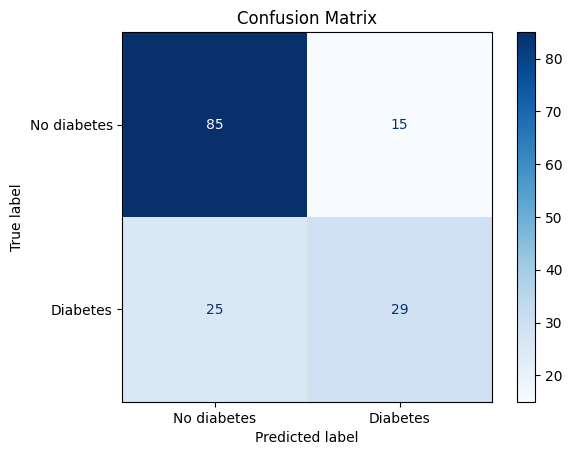

In [8]:
y_pred = best.predict(X_test)
print('Test accuracy:', round(accuracy_score(y_test, y_pred), 4))
print('(Baseline was:', round(base.score(X_test, y_test), 4), ')\n')
print(classification_report(y_test, y_pred, target_names=['No diabetes', 'Diabetes']))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                       display_labels=['No diabetes', 'Diabetes']).plot(cmap='Blues')
plt.title('Confusion Matrix')
plt.show()

## 7. Feature importance analysis

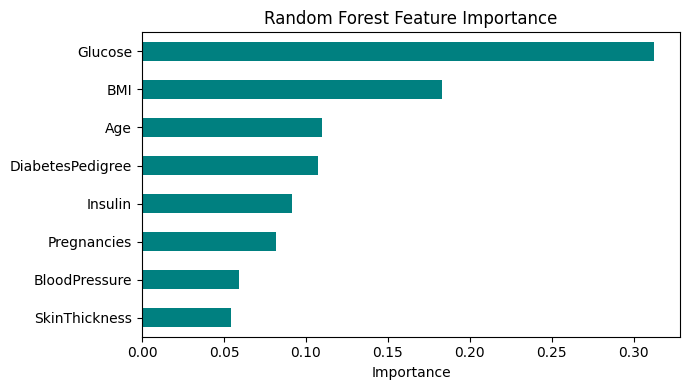

Glucose             0.3125
BMI                 0.1829
Age                 0.1101
DiabetesPedigree    0.1075
Insulin             0.0917
Pregnancies         0.0818
BloodPressure       0.0589
SkinThickness       0.0546
dtype: float64


In [9]:
imp = pd.Series(best.feature_importances_, index=X.columns).sort_values()

plt.figure(figsize=(7, 4))
imp.plot(kind='barh', color='teal')
plt.xlabel('Importance')
plt.title('Random Forest Feature Importance')
plt.tight_layout()
plt.show()

print(imp.sort_values(ascending=False).round(4))

## Summary
- Random Forest combines many decision trees, which reduces overfitting compared to a single tree.
- GridSearchCV tuned `n_estimators`, `max_depth`, `min_samples_split` and `min_samples_leaf` using 5-fold CV (best CV F1 about 0.66).
- Cross-validation gives a more reliable estimate (accuracy about 78%) than a single split.
- On the small test set (154 samples) the tuned model scored 74% vs 78% for the baseline. With so few samples, a difference of a few patients is mostly **noise**, which is why cross-validation is the better guide.
- **Glucose** is clearly the most important feature, followed by BMI and Age, which matches medical knowledge about diabetes.
- Recall for diabetic patients is only about 54-60%, because the classes are imbalanced (about 35% diabetic). Class weighting or threshold tuning could improve it.